# DIABETES PREDICTION USING LOGISTIC REGRESSION

**Student Name:** Maheshagouda N Patil

**Project:** Diabetes Prediction using Kaggle Dataset

**Algorithm:** Logistic Regression

**Dataset:** Pima Indians Diabetes Database

**Platform:** Google Colab

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("diabetes.csv")

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [8]:
# Check invalid zero values

zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for column in zero_columns:
    print(column, ":", (df[column] == 0).sum())

Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11


In [9]:
# Replace invalid zeros with NaN

df[zero_columns] = df[zero_columns].replace(0, np.nan)

print("Invalid zero values replaced successfully!")

# Check missing values again

print(df.isnull().sum())

Invalid zero values replaced successfully!
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [10]:
# Independent variables (Input)

X = df.drop("Outcome", axis=1)

# Dependent variable (Output)

y = df["Outcome"]

print("Input data shape:", X.shape)
print("Output data shape:", y.shape)

Input data shape: (768, 8)
Output data shape: (768,)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [12]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [13]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train the model

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [14]:
# Predict test data

y_pred = model.predict(X_test)

# Calculate prediction probabilities

y_prob = model.predict_proba(X_test)[:, 1]

print("Prediction completed successfully!")

print("First 10 predictions:")
print(y_pred[:10])

Prediction completed successfully!
First 10 predictions:
[1 0 0 0 0 0 1 1 0 1]


In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Accuracy :", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1 Score :", round(f1, 3))
print("ROC-AUC  :", round(roc_auc, 3))

MODEL EVALUATION RESULTS
------------------------
Accuracy : 0.734
Precision: 0.603
Recall   : 0.704
F1 Score : 0.65
ROC-AUC  : 0.813


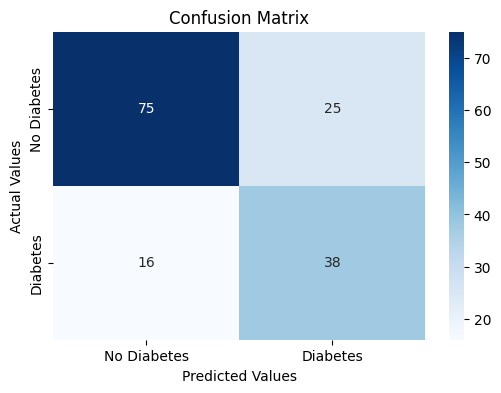

Confusion Matrix:
[[75 25]
 [16 38]]


In [16]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

print("Confusion Matrix:")
print(cm)

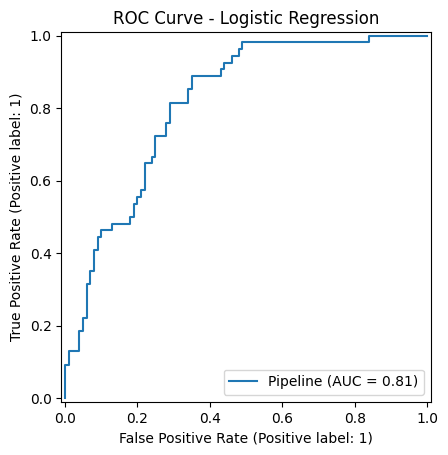

In [17]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(model, X_test,y_test)

plt.title("ROC Curve - Logistic Regression")
plt.show()

In [18]:
coefficients = model.named_steps["classifier"].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": coefficients
})

feature_importance = feature_importance.sort_values(
    by="Coefficient",
    ascending=False
)

print(feature_importance)

                    Feature  Coefficient
1                   Glucose     1.183483
5                       BMI     0.709592
0               Pregnancies     0.372902
6  DiabetesPedigreeFunction     0.287734
7                       Age     0.186434
3             SkinThickness     0.013980
2             BloodPressure    -0.014612
4                   Insulin    -0.044609


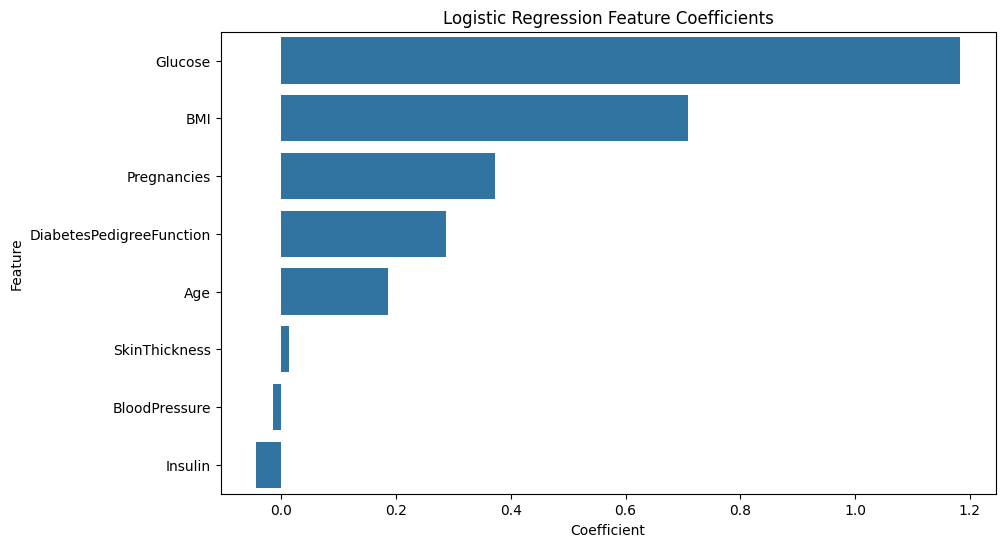

In [19]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Coefficient",
    y="Feature"
)

plt.title("Logistic Regression Feature Coefficients")
plt.show()

# FINAL CONCLUSION

In this project, we developed a Diabetes Prediction
model using Logistic Regression and the Pima Indians
Diabetes dataset.

We used eight medical features to predict diabetes.
The dataset was preprocessed using median imputation
and StandardScaler.

The model achieved:
- Accuracy: 73.4%
- Precision: 60.3%
- Recall: 70.4%
- F1-score: 65.0%
- ROC-AUC: 81.3%

Glucose and BMI showed the strongest positive
coefficients in our model.

This project helped us understand data preprocessing,
model training, prediction and evaluation using
machine learning.

The model is intended for educational purposes and
not for actual medical diagnosis.

# LIMITATIONS

1. The dataset is relatively small and historical.
2. The dataset represents a specific population.
3. Prediction accuracy depends on the quality of input data.
4. The model cannot replace professional medical diagnosis.